In [1]:
from src.data_loader import load_data

df = load_data("./data/support2.csv")

Loaded 9105 patients and 47 columns


In [2]:
df.head()

,age,death,sex,hospdead,slos,d.time,dzgroup,dzclass,num.co,edu,...,crea,sod,ph,glucose,bun,urine,adlp,adls,sfdm2,adlsc
1,62.84998,0,male,0,5,2029,Lung Cancer,Cancer,0,11.0,...,1.199951,141.0,7.459961,NaN,NaN,NaN,7.0,7.0,NaN,7.0
2,60.33899,1,female,1,4,4,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,...,5.500000,132.0,7.250000,NaN,NaN,NaN,NaN,1.0,<2 mo. follow-up,1.0
3,52.74698,1,female,0,17,47,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,...,2.000000,134.0,7.459961,NaN,NaN,NaN,1.0,0.0,<2 mo. follow-up,0.0
4,42.38498,1,female,0,3,133,Lung Cancer,Cancer,2,11.0,...,0.799927,139.0,NaN,NaN,NaN,NaN,0.0,0.0,no(M2 and SIP pres),0.0
5,79.88495,0,female,0,16,2029,ARF/MOSF w/Sepsis,ARF/MOSF,1,NaN,...,0.799927,143.0,7.509766,NaN,NaN,NaN,NaN,2.0,no(M2 and SIP pres),2.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9105 entries, 1 to 9105
Data columns (total 47 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       9105 non-null   float64
 1   death     9105 non-null   int64  
 2   sex       9105 non-null   str    
 3   hospdead  9105 non-null   int64  
 4   slos      9105 non-null   int64  
 5   d.time    9105 non-null   int64  
 6   dzgroup   9105 non-null   str    
 7   dzclass   9105 non-null   str    
 8   num.co    9105 non-null   int64  
 9   edu       7471 non-null   float64
 10  income    6123 non-null   str    
 11  scoma     9104 non-null   float64
 12  charges   8933 non-null   float64
 13  totcst    8217 non-null   float64
 14  totmcst   5630 non-null   float64
 15  avtisst   9023 non-null   float64
 16  race      9063 non-null   str    
 17  sps       9104 non-null   float64
 18  aps       9104 non-null   float64
 19  surv2m    9104 non-null   float64
 20  surv6m    9104 non-null   float64
 21  hd

In [4]:
missing = df.isna().sum()
missing_pct = missing / len(df) * 100
missing_pct.sort_values(ascending=False).head(20)

adlp       61.954970
urine      53.399231
glucose    49.423394
bun        47.797913
totmcst    38.165843
alb        37.034596
income     32.751236
adls       31.488193
bili       28.566722
pafi       25.535420
ph         25.085118
prg2m      18.110928
edu        17.946183
prg6m      17.935200
sfdm2      15.376167
totcst      9.752883
wblc        2.328391
charges     1.889072
avtisst     0.900604
crea        0.735859
dtype: float64

In [5]:
df["hospdead"].value_counts(normalize=True)

hospdead
0    0.740802
1    0.259198
Name: proportion, dtype: float64

In [6]:
for col in ["sex", "dzclass", "dzgroup", "ca", "race", "income", "dnr"]:
    print(df[col].value_counts(dropna=False))
    print()

sex
male      5125
female    3980
Name: count, dtype: int64

dzclass
ARF/MOSF              4227
COPD/CHF/Cirrhosis    2862
Cancer                1420
Coma                   596
Name: count, dtype: int64

dzgroup
ARF/MOSF w/Sepsis    3515
CHF                  1387
COPD                  967
Lung Cancer           908
MOSF w/Malig          712
Coma                  596
Colon Cancer          512
Cirrhosis             508
Name: count, dtype: int64

ca
no            5995
metastatic    1858
yes           1252
Name: count, dtype: int64

race
white       7191
black       1391
hispanic     290
other        112
asian         79
NaN           42
Name: count, dtype: int64

income
NaN           2982
under $11k    2855
$11-$25k      1527
$25-$50k      1057
>$50k          684
Name: count, dtype: int64

dnr
no dnr             5880
dnr after sadm     2956
dnr before sadm     239
NaN                  30
Name: count, dtype: int64



In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,9105.0,62.650823,15.593710,18.041990,52.797000,64.856990,73.998960,1.018480e+02
death,9105.0,0.681054,0.466094,0.000000,0.000000,1.000000,1.000000,1.000000e+00
hospdead,9105.0,0.259198,0.438219,0.000000,0.000000,0.000000,1.000000,1.000000e+00
slos,9105.0,17.863042,22.006440,3.000000,6.000000,11.000000,20.000000,3.430000e+02
d.time,9105.0,478.449863,560.383272,3.000000,26.000000,233.000000,761.000000,2.029000e+03
num.co,9105.0,1.868644,1.344409,0.000000,1.000000,2.000000,3.000000,9.000000e+00
edu,7471.0,11.747691,3.447743,0.000000,10.000000,12.000000,14.000000,3.100000e+01
scoma,9104.0,12.058546,24.636694,0.000000,0.000000,0.000000,9.000000,1.000000e+02
charges,8933.0,59995.787811,102648.778198,1169.000000,9740.000000,25024.000000,64598.000000,1.435423e+06
totcst,8217.0,30825.867768,45780.820986,0.000000,5929.566400,14452.734400,36087.937500,6.332120e+05


## Observations

- The dataset has 9105 patients and 47 columns.
- About 26% of patients died in hospital (`hospdead = 1`).
- `adlp` (62%) and `urine` (53%) have more than half of the values missing.
- `income` is missing for 33% of patients. Patients with missing income died more often (30% vs 24%), so the missing values are not random.
- `hrt`, `resp` and `meanbp` contain zeros, which are impossible for a living patient: they are probably missing measurements.
- `scoma` has many zeros, but this is correct: 0 means the patient is fully conscious.

In [8]:
from src.cleaning import clean_data

df_clean = clean_data(df)
df_clean.shape

Dropped columns: ['urine', 'adlp']
hrt: 83 zeros replaced with NaN
resp: 65 zeros replaced with NaN
meanbp: 51 zeros replaced with NaN


(9105, 45)

In [9]:
df_clean["income"].value_counts()

income
unknown       2982
under $11k    2855
$11-$25k      1527
$25-$50k      1057
>$50k          684
Name: count, dtype: int64

In [10]:
from src.analysis import mortality_by_group

mortality_by_group(df_clean, "dzgroup")

,patients,deaths,mortality_rate
dzgroup,,,
Coma,596,362,60.7
MOSF w/Malig,712,375,52.7
ARF/MOSF w/Sepsis,3515,1184,33.7
Cirrhosis,508,118,23.2
Lung Cancer,908,102,11.2
COPD,967,103,10.7
CHF,1387,87,6.3
Colon Cancer,512,29,5.7


In [11]:
mortality_by_group(df_clean, "dzclass")

,patients,deaths,mortality_rate
dzclass,,,
Coma,596,362,60.7
ARF/MOSF,4227,1559,36.9
COPD/CHF/Cirrhosis,2862,308,10.8
Cancer,1420,131,9.2


In [12]:
mortality_by_group(df_clean, "income")

,patients,deaths,mortality_rate
income,,,
unknown,2982,895,30.0
under $11k,2855,703,24.6
$11-$25k,1527,361,23.6
>$50k,684,158,23.1
$25-$50k,1057,243,23.0


In [13]:
from src.analysis import add_age_group, chi_square_test

df_clean = add_age_group(df_clean)
mortality_by_group(df_clean, "age_group").sort_index()

,patients,deaths,mortality_rate
age_group,,,
<50,1896,477,25.2
50-59,1577,358,22.7
60-69,2387,588,24.6
70-79,2199,611,27.8
80+,1046,326,31.2


In [14]:
for col in ["age_group", "sex", "ca", "dzclass", "income"]:
    p = chi_square_test(df_clean, col)
    if p < 0.001:
        print(f"{col}: p-value < 0.001")
    else:
        print(f"{col}: p-value = {p:.4f}")

age_group: p-value < 0.001
sex: p-value = 0.2697
ca: p-value < 0.001
dzclass: p-value < 0.001
income: p-value < 0.001


In [15]:
known_income = df_clean[df_clean["income"] != "unknown"]
chi_square_test(known_income, "income")

np.float64(0.6600510286446968)

## Findings

- Coma has the highest in-hospital mortality (60.7%), colon cancer the lowest (5.7%).
- After age 50, mortality increases with age (from 22.7% to 31.2% for 80+).
- Chi-square test (p < 0.05): age group, cancer status and disease class are associated with mortality.
- Sex is not associated with mortality (p = 0.27).
- Income is significant only because of the "unknown" group: among patients with known income, p = 0.66.

In [16]:
from src.analysis import compare_survived_died

vitals = ["age", "meanbp", "hrt", "resp", "temp", "crea", "sod", "scoma", "aps", "num.co"]
compare_survived_died(df_clean, vitals)

,mean_survived,mean_died,median_survived,median_died,std_survived,std_died
variable,,,,,,
age,62.29,63.69,64.53,65.97,15.45,15.95
meanbp,86.22,81.55,80.00,73.00,26.02,29.46
hrt,95.81,104.55,96.00,110.00,29.14,32.54
resp,23.30,24.06,24.00,24.00,8.89,10.73
temp,37.05,37.25,36.70,36.90,1.20,1.39
crea,1.67,2.05,1.20,1.30,1.62,1.84
sod,137.46,137.87,137.00,137.00,5.73,6.79
scoma,6.53,27.87,0.00,9.00,16.64,34.83
aps,32.00,53.61,31.00,52.00,15.68,21.90


## Survived vs died

- Patients who died had lower blood pressure (median 73 vs 80) and higher heart rate (median 110 vs 96).
- The biggest differences are in the severity scores: coma score (mean 27.9 vs 6.5) and APACHE score (53.6 vs 32.0).
- For `scoma` and `crea` the mean is much higher than the median: the distribution is skewed, so the median is more reliable.
- Surprisingly, survivors had slightly more comorbidities (1.93 vs 1.69). A possible explanation is that chronic diseases have lower in-hospital mortality than acute conditions.

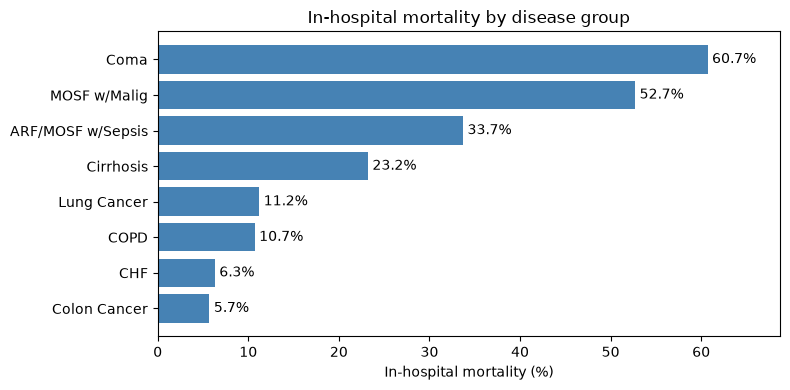

In [17]:
from src.plots import plot_mortality_by_group

table = mortality_by_group(df_clean, "dzgroup")
plot_mortality_by_group(table, "In-hospital mortality by disease group",
                        "figures/mortality_dzgroup.png")

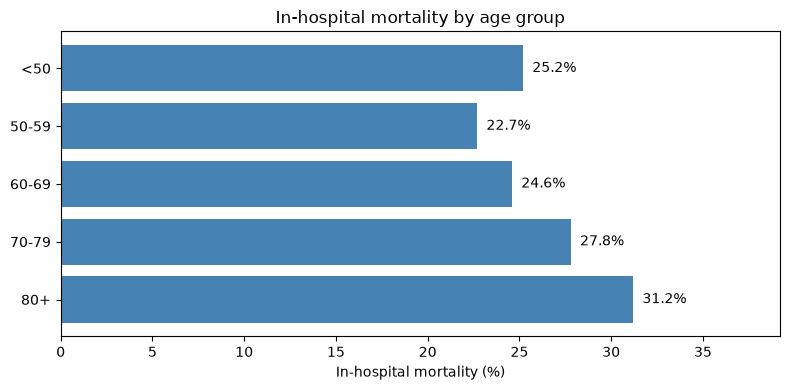

In [18]:
table = mortality_by_group(df_clean, "age_group").sort_index()
plot_mortality_by_group(table, "In-hospital mortality by age group",
                        "figures/mortality_age.png")

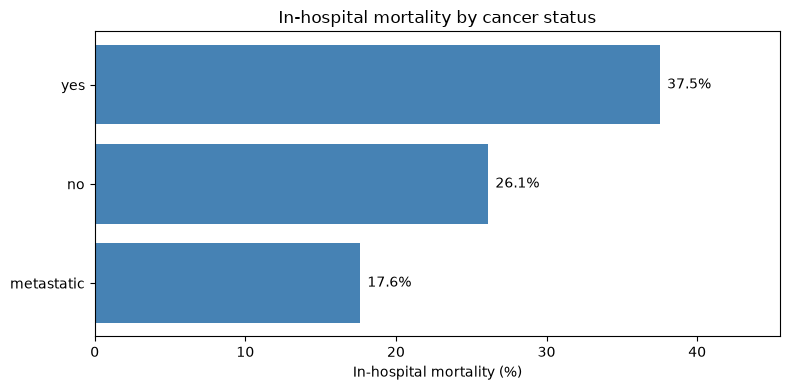

In [19]:
table = mortality_by_group(df_clean, "ca")
plot_mortality_by_group(table, "In-hospital mortality by cancer status",
                        "figures/mortality_cancer.png")

## Cancer status 

- Patients with metastatic cancer have the lowest in-hospital mortality (17.6%), but the highest overall mortality during follow-up (89%, column `death`).
- A possible explanation is that they are often discharged and die later outside the hospital: `hospdead` underestimates their risk.
- Patients with local cancer have the highest in-hospital mortality (37.5%): one third of them were admitted for multiple organ failure, a very lethal acute condition.